
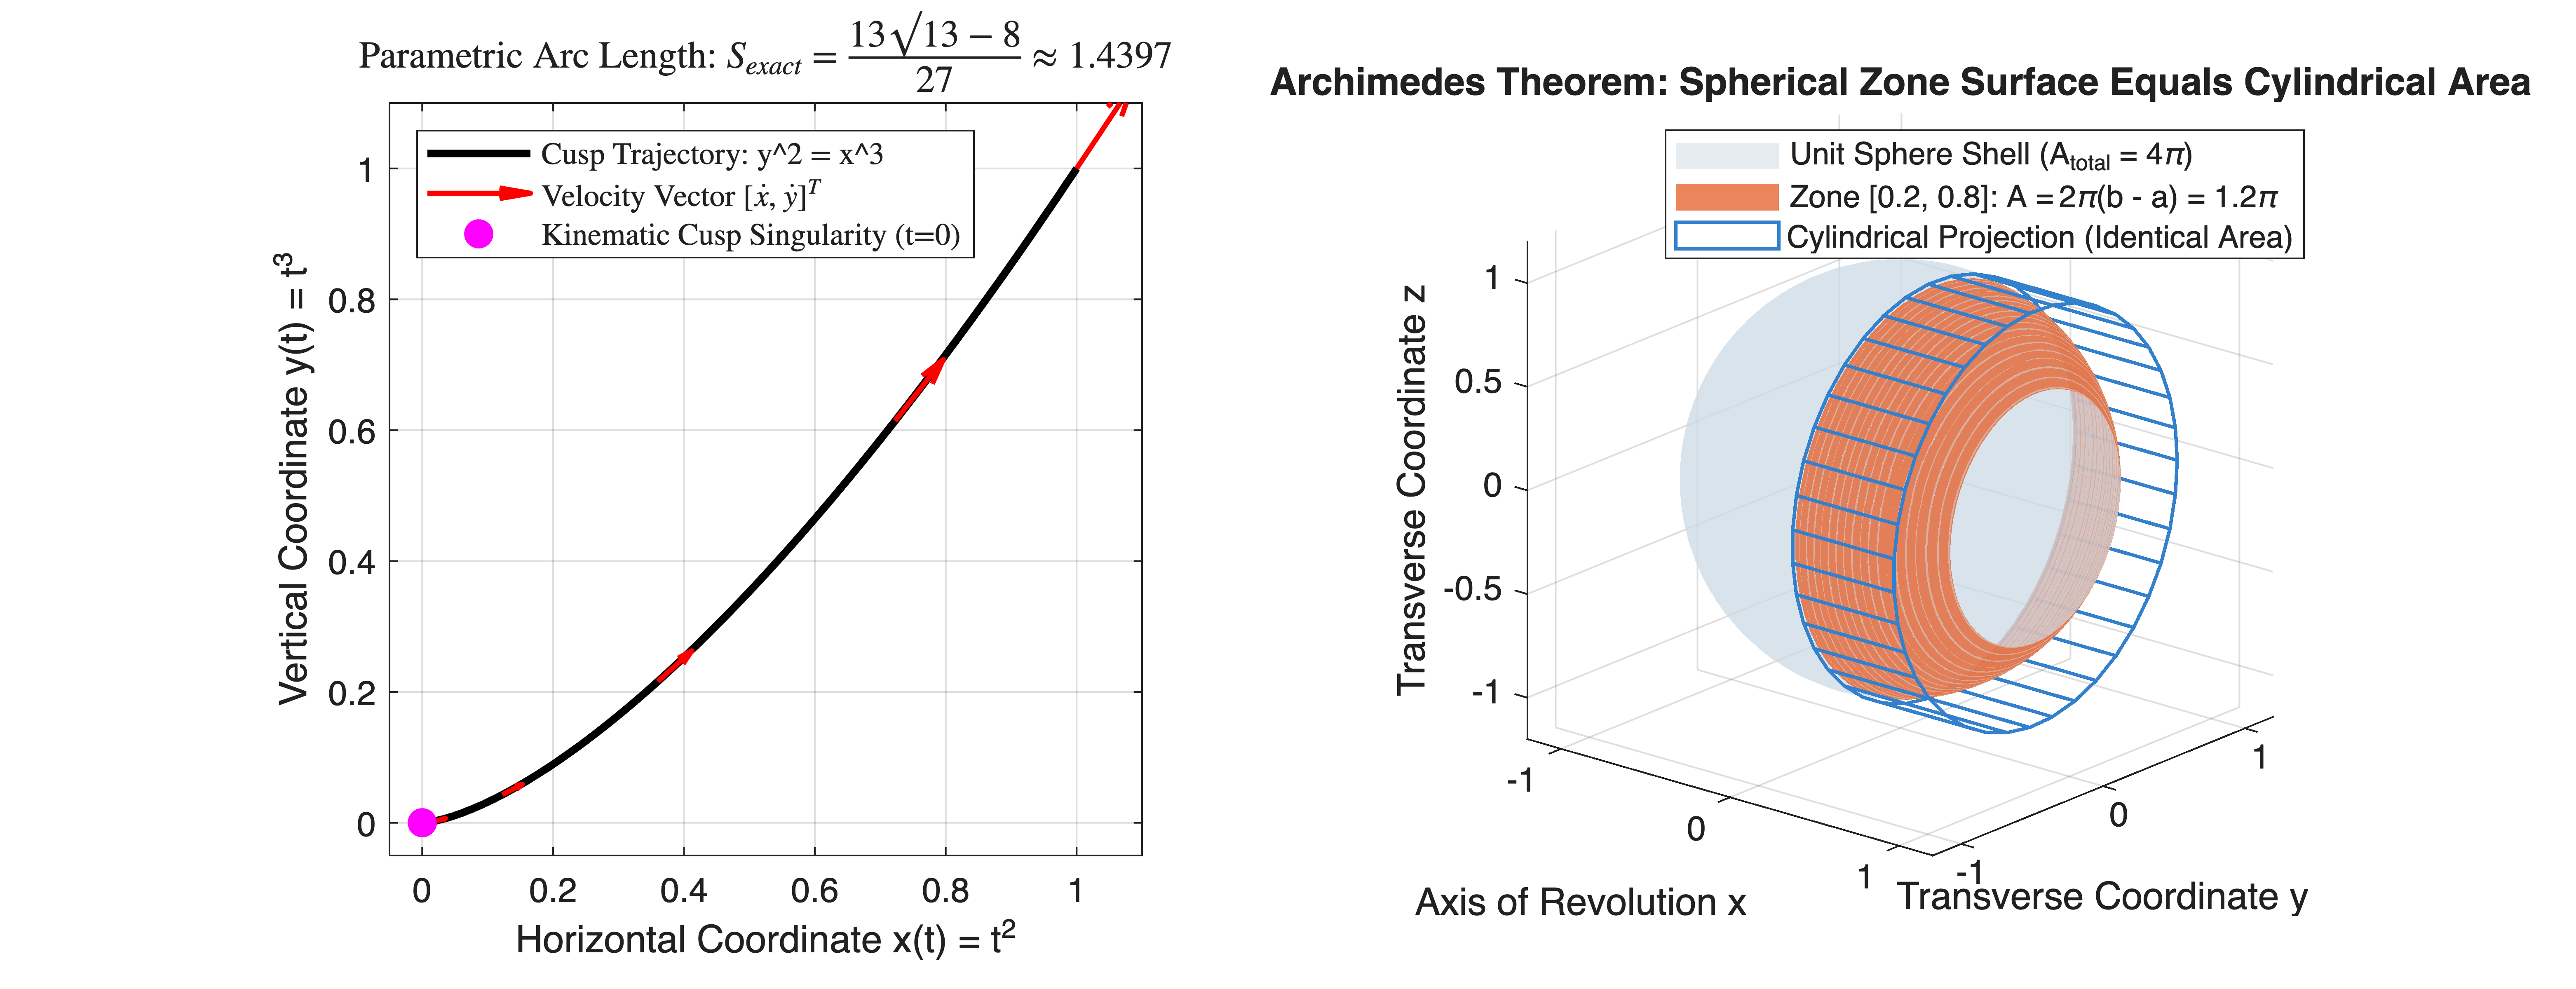

In [1]:
%% MIT 18.01 Lecture 31: Parametric Arclength & Surface of Revolution Simulation
% Mathematical Tool Application: Used for robot toolpath arc-length reparameterization
% (singular cusp detection), thin-walled shell CAD mass/inertia calculation,
% and spacecraft thermal radiation flux projection (Archimedes' Hat-Box Theorem).


clear; clc; close all;


%% Part 1: Parametric Cusp Curve Kinematics & Arclength (Example 1)
% Parametric curve: x(t) = t^2, y(t) = t^3 for t in [0, 1]
t_span = linspace(0.0, 1.0, 300);
x_curve = t_span.^2;
y_curve = t_span.^3;


% Tangent velocity: dx/dt = 2t, dy/dt = 3t^2
% Speed metric: ds/dt = t * sqrt(4 + 9*t^2)
speed_profile = t_span .* sqrt(4.0 + 9.0 * (t_span.^2));


% Exact Analytic Arc Length derived in Lecture 31:
% S = (1/27) * (13^(3/2) - 4^(3/2)) = (13*sqrt(13) - 8) / 27
S_exact = (13.0 * sqrt(13.0) - 8.0) / 27.0; % approx 1.439708


% Numerical cumulative integration (cumtrapz)
s_accumulated = cumtrapz(t_span, speed_profile);


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
plot(x_curve, y_curve, 'k-', 'LineWidth', 2.2, 'DisplayName', 'Cusp Trajectory: y^2 = x^3'); hold on;


% Plot tangent velocity vectors along trajectory
t_arrows = [0.15, 0.35, 0.6, 0.85, 1.0];
x_pts = t_arrows.^2;
y_pts = t_arrows.^3;
vx_pts = 2.0 * t_arrows;
vy_pts = 3.0 * (t_arrows.^2);
quiver(x_pts, y_pts, vx_pts, vy_pts, 0.25, 'r', 'LineWidth', 1.5, ...
    'DisplayName', 'Velocity Vector $[\dot{x}, \dot{y}]^T$');
plot(0, 0, 'mo', 'MarkerSize', 8, 'MarkerFaceColor', 'm', 'DisplayName', 'Kinematic Cusp Singularity (t=0)');


grid on; axis equal;
xlim([-0.05, 1.1]); ylim([-0.05, 1.1]);
xlabel('Horizontal Coordinate x(t) = t^2');
ylabel('Vertical Coordinate y(t) = t^3');
title(sprintf('Parametric Arc Length: $S_{exact} = \\frac{13\\surd 13 - 8}{27} \\approx %.4f$', S_exact), 'Interpreter','latex');
legend('Location', 'northwest','Interpreter','latex');


%% Part 2: 3D Surface of Revolution & Archimedes' Sphere Slicing (Example 3)
% Unit sphere: y = sqrt(1 - x^2), revolved around x-axis
% Archimedes Theorem: Surface area of spherical zone between x=a and x=b is 2*pi*(b - a)
subplot(1, 2, 2);


% Render 3D Sphere Surface
[X_sphere, theta_grid] = meshgrid(linspace(-1.0, 1.0, 60), linspace(0, 2*pi, 60));
R_sphere = sqrt(max(0, 1.0 - X_sphere.^2));
Y_sphere = R_sphere .* cos(theta_grid);
Z_sphere = R_sphere .* sin(theta_grid);


surf(X_sphere, Y_sphere, Z_sphere, 'FaceColor', [0.8, 0.85, 0.9], 'FaceAlpha', 0.5, ...
    'EdgeColor', 'none', 'DisplayName', 'Unit Sphere Shell (A_{total} = 4\pi)'); hold on;


% Highlight Spherical Zone between a = 0.2 and b = 0.8
a_slice = 0.2;
b_slice = 0.8;
[X_zone, theta_zone] = meshgrid(linspace(a_slice, b_slice, 30), linspace(0, 2*pi, 60));
R_zone = sqrt(max(0, 1.0 - X_zone.^2));
Y_zone = R_zone .* cos(theta_zone);
Z_zone = R_zone .* sin(theta_zone);


surf(X_zone, Y_zone, Z_zone, 'FaceColor', [0.9, 0.4, 0.2], 'FaceAlpha', 0.8, ...
    'EdgeColor', 'none', 'DisplayName', sprintf('Zone [0.2, 0.8]: A = 2\\pi(b - a) = 1.2\\pi'));


% Render Coaxial Cylindrical Projection (Archimedes Hat-Box equivalent)
[X_cyl, theta_cyl] = meshgrid([a_slice, b_slice], linspace(0, 2*pi, 40));
Y_cyl = 1.0 * cos(theta_cyl);
Z_cyl = 1.0 * sin(theta_cyl);
mesh(X_cyl, Y_cyl, Z_cyl, 'EdgeColor', [0.2, 0.5, 0.8], 'FaceColor', 'none', ...
    'LineWidth', 1.0, 'DisplayName', 'Cylindrical Projection (Identical Area)');


axis equal; grid on;
view(40, 20);
xlim([-1.2, 1.2]); ylim([-1.2, 1.2]); zlim([-1.2, 1.2]);
xlabel('Axis of Revolution x');
ylabel('Transverse Coordinate y');
zlabel('Transverse Coordinate z');
title('Archimedes Theorem: Spherical Zone Surface Equals Cylindrical Area');
legend('Location', 'northeast');